## Prediction of dinucleotide steps in DNA hexamers

### General idea:

The main question addressed here is whether a short DNA sequence (a two-nucleotide fragment, also called a *dinucleotide step*) influences its immediate environment strongly enough to produce a distinct, sequence-dependent geometric signature. If so, the identities of nucleobases within the two-nucleotide fragment should be predictable from the geometry of the surrounding nucleotides and potentially also from their sequence (base identities).

This pipeline employs several neural network architectures to test the predictability of dinucleotide steps. Specifically, based on geometric and/or sequence information about nucleotides flanking the central step, the models attempt to predict the identities of the step nucleobases within a DNA hexamer. Schematically:

```
5'-ACy₁y₂GA-3'
3'-TGy₃y₄CT-5'
```

`y₁`–`y₄` represent the unknown identities of nucleobases in the central step. Models take as input geometric information about flanking nucleotides in both strands (`AC--GA` and `TG--CT`), specifically, a matrix of distances between selected atoms. In the current implementation, five atoms from each nucleotide are selected (three backbone and two base atoms). Thus, for the whole hexamer, 5 atoms × 6 nucleotides × 2 strands = 60 atoms are selected for pairwise distance calculations, giving a 60×60 distance matrix. After removing the atoms belonging to the central step, the resulting 40×40 distance matrix constitutes the geometric input to the model.

Representing structural data as interatomic distance matrices is convenient because this representation is invariant under rotation and translation. Moreover, selecting only a few atoms per nucleotide for distance calculations is justified by the relative rigidity of certain parts of nucleotide structures, which makes an all-atom distance matrix highly redundant and unnecessarily large. 

Models may also take additional input in the form of sequence information about flanking nucleotides (`5'-ACGA-3'` and `3'-TGCT-5'` in the example above).

### Data:

There are 2,080 unique DNA hexamer sequences. For each of them, MD-sampled geometries (in the form of 60×60 distance matrices) are stored in separate files. File names contain the corresponding sequences, from which input sequence information and target labels are derived. Two datasets are available:

1. With 100 samples per hexamer — 208,000 samples in total.
2. With 500 samples per hexamer — 1,040,000 samples in total.

The datasets are additionally augmented by generating reverse-complementary inputs. Because the DNA double helix consists of two antiparallel, complementary strands, the same duplex can be represented by either strand. For example, `5'-ATTGCA-3'` and `5'-TGCAAT-3'` represent the same duplex viewed from opposite strands. However, depending on which strand is used as the reference, the target sequences differ (`TG` and `CA`, respectively).

Thus, for simplicity, all reverse-complementary sequences are added explicitly, and the corresponding distance matrices are obtained by simply rearranging the original matrices. This allows the models to process both strand orientations, with the corresponding target labels.

### Implementation:

In this pipeline, several model architectures and strategies are tested for their predictive performance. In particular, simple MLP and CNN classifiers and their *complementarity-aware* variants are trained using geometric information, optionally combined with sequence information, to predict the identity of the central step. Prediction can be formulated either as a 16-class classification problem (16 possible dinucleotide sequences) or as two separate 4-class classification problems (each nucleotide in the step predicted separately).

#### Models:

`MLP`: A simple network that takes geometric information in the form of a vector (the upper triangle of the distance matrix) and optionally sequence information. It can perform either 16-class or two separate 4-class classifications.

`CR_MLP`: A network that processes geometric information from the perspectives of both DNA strands. It first processes the geometry of one strand and generates prediction logits. Then, it processes the reverse-complementary (CR) representation of the geometry, with the first-stage logits added to the second-stage input. The model returns the second-stage logits, reordered to match the original strand's target labels.

`CRds_MLP`: Similar to `CR_MLP`, but the model returns logits for both strands. This architecture is combined with a complementarity-aware loss function that additionally penalizes inconsistent predictions between the two strands.

`CNN`: A convolutional neural network that, unlike `MLP`, takes 2D distance matrices as input and performs convolutions before passing the flattened output through an MLP block. It can also take optional sequence information (added to the flattened convolutional output) and perform either 16-class or two separate 4-class classifications.

`CR_CNN`: Uses the same strategy as `CR_MLP`, but with convolutional layers. Logits from the first strand are added to the flattened convolutional output during second-strand processing.

`CRds_CNN`: Uses the same strategy as `CRds_MLP`. As in `CR_CNN`, logits from the first strand are added to the flattened convolutional output during second-strand processing.

#### Workflow

The pipeline allows models to be conveniently trained in different configurations (with different loss functions, input/output formats, and hyperparameters). The `Trainer` class combines several functionalities, including model training, evaluation on the test set, accuracy calculation, and saving model weights. It also stores information about the model configuration, hyperparameters, loss function, and input/output formats.

The `make_trainer` function simplifies the initialization of `Trainer` objects by automatically selecting compatible models, loss functions, and datasets based on the provided configuration and hyperparameters. Thus, creating multiple trainer objects in a loop makes it easy to configure, train, and evaluate different models automatically.

### Analysis

Model predictions on the test set can be visualized using confusion matrices, showing how frequently each class is correctly predicted or confused with other classes. The matrices can be plotted as heatmaps and saved as `.png` files.

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path

import numpy as np
#import pandas as pd
#import matplotlib.pyplot as plt

import torch

from Utils import *
from Models import *
from Trainer import trainer
from Models_utils import CRConsistencyLoss, EnhancedLoss

In [3]:
MAT_DIR = Path("dist_mat_sample100")   # path to directory with .npz files with distance matrices
Y_NTS = [3, 4]                         # 1-based indices of nucleotides in hexamer to be predicted 
AT_PER_NT = 5                          # Number of atoms in each nucleotide considered for distance matrix calculations
TRAIN_SIZE = 0.70                      # Fraction of the dataset that goes to training set
VAL_SIZE = 0.10                        # Fraction of the dataset that goes to validation set
COMP_DICT = {                          # Complementary rules; how nucleotides pair with each other 
    "A": "T",
    "T": "A",
    "G": "C",
    "C": "G"
}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load and process data

In [4]:
# Get list of input files 
files = list(MAT_DIR.glob("*.npz"))

In [5]:
# Firts iterate over input files and collect y and X sequences
# and information about distance matrix shapes to initiate array

X_seq = []
y = []
seq_ranges = {}

total_samples = 0
mat_sizes = []
for p in files:

    # Get number of smaples in each npz file and size of distance matrices 
    # (size must be the same across all samples and all files)
    shape = np.load(p)['arr_0'].shape
    n_samples = shape[0]
    
    # Check if matrices are square 
    if shape[-2] != shape[-1]:
        raise ValueError("Not square matrices")
        
    mat_sizes.append(shape[-2])

    # Check if distance matrices have the same sizes across files
    if len(set(mat_sizes)) > 1:
        raise ValueError("Matrices have different shapes between npz files.")

    # Get hexamer sequence
    hex_seq = p.name.split("_")[0]
    
    # Get complementary reversed hexamer sequence
    hex_seq_compl_rev = compl_rev_seq(hex_seq)

    # Process sequences
    # The same sequence corresponds to n_samples in the loaded file; appends y list
    # with nts defined by Y_NTS n_samples times for sequence and its complementary reverse
    y += ["".join(b for i, b in enumerate(hex_seq, 1) if i in Y_NTS)] * n_samples
    y += ["".join(b for i, b in enumerate(hex_seq_compl_rev, 1) if i in Y_NTS)] * n_samples

    # As above but for remaining nts in sequence (those not in Y_NTS)
    X_seq += ["".join(b for i, b in enumerate(hex_seq, 1) if i not in Y_NTS)] * n_samples
    X_seq += ["".join(b for i, b in enumerate(hex_seq_compl_rev, 1) if i not in Y_NTS)] * n_samples

    # Get sequence ranges -- index ranges of samples corresponding to given sequence
    seq_ranges[hex_seq] = (total_samples, total_samples + n_samples * 2)
    
    total_samples += n_samples * 2

In [6]:
# Init X array
mat_size = mat_sizes[0] - 2 * AT_PER_NT * len(Y_NTS)

X_mat = np.empty((total_samples, mat_size, mat_size), dtype=np.float32)

In [7]:
# Load distance matrices from all files to preinitiated X array

for p, (seq, rng) in zip(files, seq_ranges.items()):
    if not p.name.split("_")[0] == seq:
        values = np.load(list(files[0].parent.glob(f"{seq}*"))[0])["arr_0"]
    else:
        values = np.load(p)["arr_0"]

    values = values.astype(np.float32, copy=False)

    values = remove_nts(values, Y_NTS)
    values_rc = compl_rev_X(values, seq_len=4)

    range_mid = rng[0] + (rng[1] - rng[0]) // 2

    X_mat[rng[0] : range_mid] = values
    X_mat[range_mid : rng[1]] = values_rc

In [8]:
# Preapre distance vectors -- instead of using matrices (symmetric -- redundant), 
# extract only upper triangle with unique distance values and convert it to 1D vector
X_vec = upper_triangle_to_vector(X_mat)

In [ ]:
# Get sample indices for train, validation and test sets 

train_ind, val_ind, test_ind, split_info = Train_Val_Test_Indices(
    seq_ranges, 
    train_fraction=TRAIN_SIZE, 
    val_fraction=VAL_SIZE,
    mode="by_hexamer",
    seed=42
)

In [ ]:
# Standarize X (in matrix and vector forms)

# Standarize X as matrices
mat_mean, mat_std = Standarize_inplace(X_mat, train_ind)

# Standarize X as vectors
vec_mean, vec_std = Standarize_inplace(X_vec, train_ind)

In [10]:
# Define base -- integer or base-step -- integer mappings for sequence encoding 

# base -- integer mapping
base_dict = {k:v for v, k in enumerate(["A", "G", "C", "T"])}   # !!! This order matters 
base_dict_rev = {v:k for k, v in base_dict.items()}   # For results decoding

# step -- integer mapping 
step_dict = {k:v for v, k in enumerate(np.unique(y))}
step_dict_rev = {v:k for k, v in step_dict.items()}   # For results decoding

In [11]:
# Define indices mappings for complementary bases and complementary reversed steps

step_CR_ind_mapping = {v: step_dict[compl_rev_seq(k)] for k, v in step_dict.items()}
base_CR_ind_mapping = {v: base_dict[compl_rev_seq(k)] for k, v in base_dict.items()}

In [12]:
# encode X_seq -- simply convert string to list of integers corresponding to letters
X_seq_encoded = np.array([[base_dict[b] for b in s] for s in X_seq])

In [13]:
# encode y: 
# y_encoded_join: 2-nts-step encoded as individual classes (y: n; n={0,15})
# y_encoded_sep: each position in 2-nts-step encoded separately (y: [n, m]; n,m={0,3})

# treat each of 16 2-nucletide steps as individual class and encode them
# jointly -- produces 16 classes encoded as integers ranging from 0 to 15. 
y_encoded_join = np.array([step_dict[i] for i in y])
    
# encode nucleotides at two positions in a step separately (4 classes 
# per position) -- produces list of two integers ranging from 0 to 3 
# !!! For this encoding, in the model's settings: out_size=8, out_reshape=True
y_encoded_sep = np.array([[base_dict[b] for b in s] for s in y])

In [14]:
# Convert numpy arrays into pytorch tensors 

# X geometry (matrix)
X_mat = torch.from_numpy(X_mat)

# X geometry (vector)
X_vec = torch.from_numpy(X_vec)

# X sequence
X_seq_encoded = torch.from_numpy(X_seq_encoded)

# y joined
y_encoded_join = torch.from_numpy(y_encoded_join)

# y separate
y_encoded_sep = torch.from_numpy(y_encoded_sep)

In [16]:
# Prepare datasets for different models

# Model: geometry (vector)
Dset_vec_join = DataSet(X=X_vec, y=y_encoded_join, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)
Dset_vec_sep = DataSet(X=X_vec, y=y_encoded_sep, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)

# Model: geometry (vector) + seq
Dset_vec_seq_join = DataSet(X=[X_vec, X_seq_encoded], y=y_encoded_join, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)
Dset_vec_seq_sep = DataSet(X=[X_vec, X_seq_encoded], y=y_encoded_sep, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)

# Model: geometry (matrix)
Dset_mat_join = DataSet(X=X_mat, y=y_encoded_join, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)
Dset_mat_sep = DataSet(X=X_mat, y=y_encoded_sep, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)

# Model: geometry (matrix) + seq
Dset_mat_seq_join = DataSet(X=[X_mat, X_seq_encoded], y=y_encoded_join, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)
Dset_mat_seq_sep = DataSet(X=[X_mat, X_seq_encoded], y=y_encoded_sep, train_idx=train_ind, test_idx=test_ind, val_idx=val_ind)

## Define models and datasets characteristics

In [17]:
# Define mapping for datasets -- dictionary with tuple keys 
# containing dataset keywords / characteristics:
# (type of geometric X, with sequence X, type of y)

DATASETS = {
    ("vec", False, "joined"): Dset_vec_join,
    ("vec", False, "separate"): Dset_vec_sep,
    ("vec", True,  "joined"): Dset_vec_seq_join,
    ("vec", True,  "separate"): Dset_vec_seq_sep,

    ("mat", False, "joined"): Dset_mat_join,
    ("mat", False, "separate"): Dset_mat_sep,
    ("mat", True,  "joined"): Dset_mat_seq_join,
    ("mat", True,  "separate"): Dset_mat_seq_sep,
}

In [18]:
# Define models configurations 
# Model name: (model class, accepted input type, model type)

MODEL_CONFIG = {
    "MLP":      (Simple_MLP_seq,  "vec", "standard"),
    "CR_MLP":   (CR_MLP_seq,      "vec", "cr"),
    "CRds_MLP": (CRds_MLP_seq,    "vec", "cr_ds"),
    "CNN":      (CNN_2D_seq,      "mat", "standard"),
    "CR_CNN":   (CR_CNN_2D_seq,   "mat", "cr"),
    "CRds_CNN": (CRds_CNN_2D_seq, "mat", "cr_ds"),
}

## Define variants of hyperparameters

In [19]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_sizes": [[1024, 512, 128, 64]]
    },
    "CR_MLP": {
        "hidden_sizes": [[1024, 512, 128, 64], [512, 256, 128, 64]]
    },
    "CRds_MLP": {
        "hidden_sizes": [[1024, 512, 128, 64]],
        "logits_dropout": [0.0],
        "detach_logits": [True, False],
    },
    "CNN": {
        "hidden_sizes": [[128, 64]],
        "conv_channels": [[16, 32, 64]],
        "kern_sizes": [[(3, 3), (3, 3), (3, 3)]],
        "pool_bias": [False],
        "pool_act": [None],
        "pool_normW": [False],
    },
    "CR_CNN": {
        "hidden_sizes": [[128, 64]],
        "conv_channels": [[16, 32, 64]],
        "kern_sizes": [[(3, 3), (3, 3), (3, 3)]],
        "pool_bias": [False],
        "pool_act": [None],
        "pool_normW": [False],
    }, 
    "CRds_CNN": {
        "hidden_sizes": [[128, 64]],
        "logits_dropout": [0.0],
        "detach_logits": [False],
        "conv_channels": [[16, 32, 64]],
        "kern_sizes": [[(3, 3), (3, 3), (3, 3)]],
        "pool_bias": [False, True],
        "pool_act": [None],
        "pool_normW": [False, True],
    }
}

In [20]:
LOSS_PARAMS = {
    "Enhanced": {
        "pair_weight": [0.5, 1.0]
    },
    "CRConsistency": {
        "consistency_weight": [0.15]
    }
}

## Configure Trainer objects

### Some helper functions

In [21]:
def get_model_param_set(model_name):
    """
    Prepares sets of model's parameters by combining 
    all variants of given parameter defined in MODEL_PARAMS
    """

    if model_name not in MODEL_PARAMS:
        raise ValueError(f"Unknown model name: {model_name}")
        
    hyperparams_set = {}
    
    for i, parms in enumerate(
        itertools.product(
            *MODEL_PARAMS[model_name].values()
        ), 1
    ):
        kwargs = {
            k: v for k, v in
            zip(MODEL_PARAMS[model_name].keys(), parms)
        }
    
        hyperparams_set[f"Mset_{i}"] = kwargs

    return hyperparams_set

In [22]:
def get_loss_param_set(loss_name):
    if loss_name not in LOSS_PARAMS:
        raise ValueError(f"Unknown loss function name: {loss_name}")

    hyperparams_set = {}
    
    for i, parms in enumerate(
        itertools.product(
            *LOSS_PARAMS[loss_name].values()
        ), 1
    ):
        kwargs = {
            k: v for k, v in
            zip(LOSS_PARAMS[loss_name].keys(), parms)
        }
    
        hyperparams_set[f"Lset_{i}"] = kwargs

    return hyperparams_set

In [23]:
def make_trainer(model_name, y_form="joined", with_seq=False, epochs=1,
                 device=DEVICE, model_kwargs=None, loss_kwargs=None):
    """
    Initialize a trainer with the appropriate model, loss and dataset.

    Optional keyword arguments can be passed independently to the
    model and loss function.
    """

    if model_name not in MODEL_CONFIG:
        raise ValueError(f"Unknown model: {model_name}")

    if y_form not in ("joined", "separate"):
        raise ValueError("y_form must be 'joined' or 'separate'")

    model_class, input_type, model_family = MODEL_CONFIG[model_name]
    dataset = DATASETS[(input_type, with_seq, y_form)]

    # Model configuration
    model_params = dict(model_kwargs or {})
    model_params.update(
        out_reshape=(y_form == "separate"),
        with_seq=with_seq
    )

    if model_family != "standard":
        model_params.setdefault("base_mapping", base_CR_ind_mapping)   # global var.
        model_params.setdefault("step_mapping", step_CR_ind_mapping)   # global var.

    # Loss function selection
    if model_family == "cr_ds":
        loss_class = CRConsistencyLoss
        loss_name = "CRConsistency"
    elif y_form == "separate":
        loss_class = EnhancedLoss
        loss_name = "Enhanced"
    else:
        loss_class = nn.CrossEntropyLoss
        loss_name = "CrossEntropy"

    # Initialize objects
    model = model_class(**model_params)
    criterion = loss_class(**(loss_kwargs or {}))

    info = {
        "model": model_name,
        "model_family": model_family,
        "with_seq": with_seq,
        "y_form": y_form,
        "model_parameters": model_kwargs,
        "loss_function": loss_name,
        "loss_parameters": loss_kwargs,
        "test_pred_config": {
            "sep_nts": y_form == "separate",
            "ds_out": model_family == "cr_ds",
            "label_mapping": base_dict_rev if y_form == "separate" else step_dict_rev   # global var.
        }
    }
    
    #params = {"epochs": 1, **(trainer_kwargs or {})}

    return trainer(
        model=model,
        criterion=criterion,
        train_loader=dataset.train_loader,
        test_loader=dataset.test_loader,
        val_loader=dataset.val_loader,
        epochs=epochs,
        device=device,
        info=info
    )


### Configure multiple Trainers at once 

In [24]:
"""
Combine different model configurations and hyperparemeter configurations.
Essentially produces trainer objects for all possible combinations of: 
  models: ['MLP', 'CR_MLP', 'CRds_MLP', 'CNN', 'CR_CNN', 'CRds_CNN']
  y froms: ["separate", "joined"]
  presence of X sequence: [True, False]
  models hyperparameters: defined in MODEL_PARAMS
  loss function parameters: defined in LOSS_PARAMS
"""

# ['MLP', 'CR_MLP', 'CRds_MLP', 'CNN', 'CR_CNN', 'CRds_CNN']
model_variants = ['CRds_CNN']

# ["separate", "joined"]
y_form_variants = ["separate"]

# [True, False]
with_seq_variants = [True]

all_trainers = {}

for mod, y_form, with_s in itertools.product(
    model_variants, 
    y_form_variants, 
    with_seq_variants
):
    # get model parameter variants
    model_params_variants = get_model_param_set(mod)

    # get loss parameter variants
    if MODEL_CONFIG[mod][2] == "cr_ds":
        loss_params_variants = get_loss_param_set("CRConsistency")
    elif y_form == "separate":
        loss_params_variants = get_loss_param_set("Enhanced")
    else:
        loss_params_variants = {'Lset_1': None}

    # Iterate over model and loss parameter variants
    # for each model setup 
    for ms, ls in itertools.product(
        model_params_variants,
        loss_params_variants
    ):
        # define trainer ID
        seq_intr = "_seq_" if with_s else "_"
        y_suffix = "join" if y_form == "joined" else "sep"
        model_set_id = f"_{ms}" if len(model_params_variants) > 1 else ""
        loss_set_id = f"_{ls}" if len(loss_params_variants) > 1 else ""
        trainer_id = f"{mod}{seq_intr}{y_suffix}{model_set_id}{loss_set_id}"

        # define model and loss hyperparams
        model_hyper = model_params_variants[ms]
        
        if loss_params_variants[ls] is None:
            loss_hyper = None
        else:
            loss_hyper = loss_params_variants[ls]
            
        # Add trained to dict
        all_trainers[trainer_id] = make_trainer(
            model_name=mod, 
            with_seq=with_s, 
            y_form=y_form, 
            epochs=20,
            device=DEVICE,
            model_kwargs=model_hyper,
            loss_kwargs=loss_hyper
        )

In [25]:
all_trainers

{'CRds_CNN_seq_sep_Mset_1': <Trainer.trainer at 0x7fe87c60e210>,
 'CRds_CNN_seq_sep_Mset_2': <Trainer.trainer at 0x7fe874990dd0>,
 'CRds_CNN_seq_sep_Mset_3': <Trainer.trainer at 0x7fe8749c7790>,
 'CRds_CNN_seq_sep_Mset_4': <Trainer.trainer at 0x7fe8749dab10>}

In [26]:
print(f"Prepared {len(all_trainers)} trainers.")

Prepared 4 trainers.


## Train models

In [27]:
for trn_id in all_trainers:
    all_trainers[trn_id].train()

Epoch: 1, batch: 1000, loss: 1.3863965210914613
Epoch: 1, batch: 2000, loss: 1.3861081896424294
Epoch: 1, batch: 3000, loss: 1.3857510895729066
Epoch: 1, batch: 4000, loss: 1.385427895307541
Epoch: 1, batch: 5000, loss: 1.3848726446151733
Epoch: 1, batch: 6000, loss: 1.3837495440642038
Epoch: 1, batch: 7000, loss: 1.3819510637692043
Epoch: 1, batch: 8000, loss: 1.3793182512819766
Epoch: 1, batch: 9000, loss: 1.3751415552298227
Loss on test set: 1.324734991171629

Epoch: 2, batch: 1000, loss: 1.305023997426033
Epoch: 2, batch: 2000, loss: 1.293479115009308
Epoch: 2, batch: 3000, loss: 1.2846410216887791
Epoch: 2, batch: 4000, loss: 1.2781942715644836
Epoch: 2, batch: 5000, loss: 1.2714859894752502
Epoch: 2, batch: 6000, loss: 1.2655823503335317
Epoch: 2, batch: 7000, loss: 1.2605322059903825
Epoch: 2, batch: 8000, loss: 1.25496463945508
Epoch: 2, batch: 9000, loss: 1.2498854304419624
Loss on test set: 1.2105872047002755

Epoch: 3, batch: 1000, loss: 1.20221384036541
Epoch: 3, batch: 200

## Evaluate models

In [28]:
for trn_id in all_trainers:

    all_trainers[trn_id].restore_best_model()
    _ = all_trainers[trn_id].predict_test(
        **all_trainers[trn_id].info['test_pred_config']
    )

In [29]:
for trn_id in all_trainers:
    test_acc_round = np.round(all_trainers[trn_id].test_accuracy(), 4)
    print(f"Model variant: {trn_id}, accuracy: {test_acc_round}")

Model variant: CRds_CNN_seq_sep_Mset_1, accuracy: 0.2625
Model variant: CRds_CNN_seq_sep_Mset_2, accuracy: 0.2634
Model variant: CRds_CNN_seq_sep_Mset_3, accuracy: 0.2614
Model variant: CRds_CNN_seq_sep_Mset_4, accuracy: 0.2659


## Analyze

In [30]:
# Calculate confusion matrices that show how often (in %) different 
# classes were confused with other classes by the model.

all_confusion_matrices = {}

for trn_id in all_trainers:
    all_confusion_matrices[trn_id] = get_confusion_matrix(all_trainers[trn_id].test_predictions)

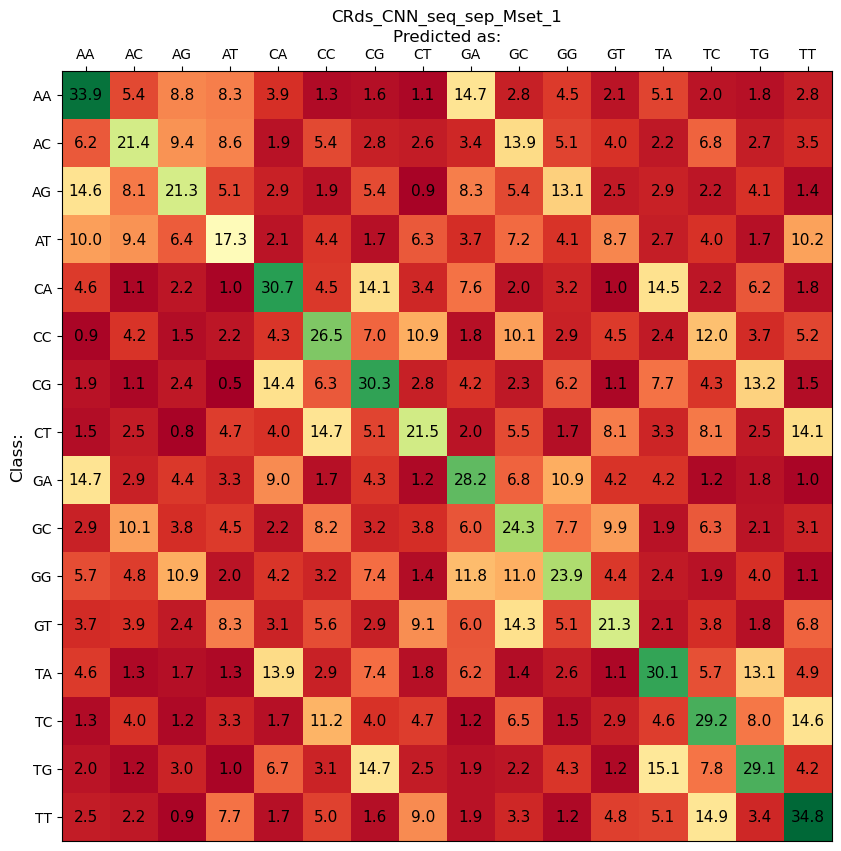

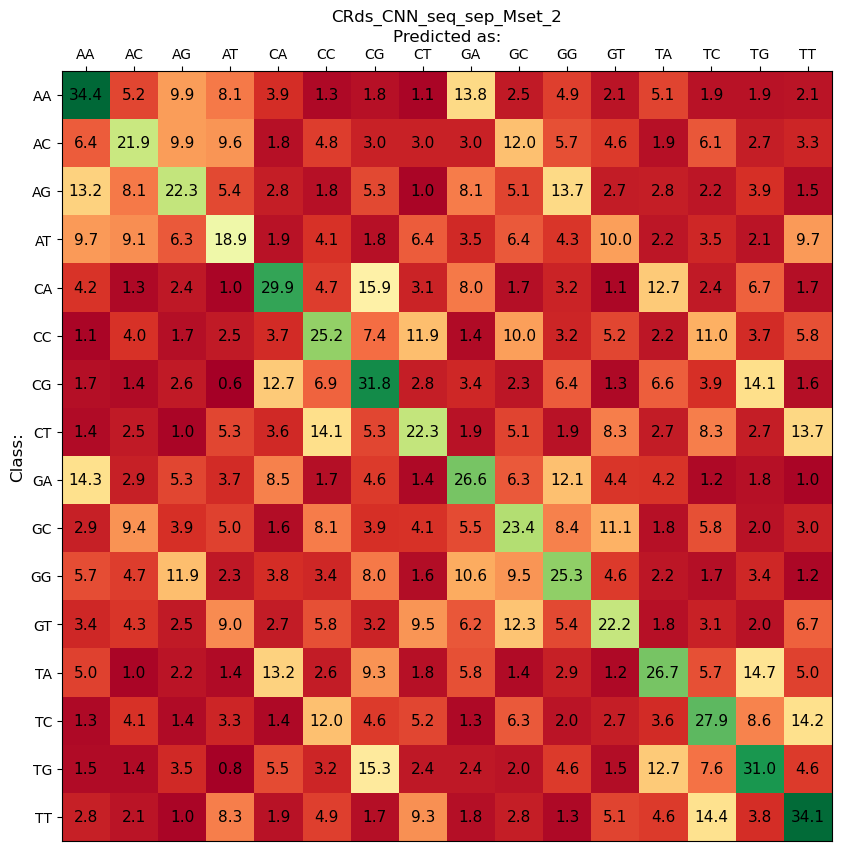

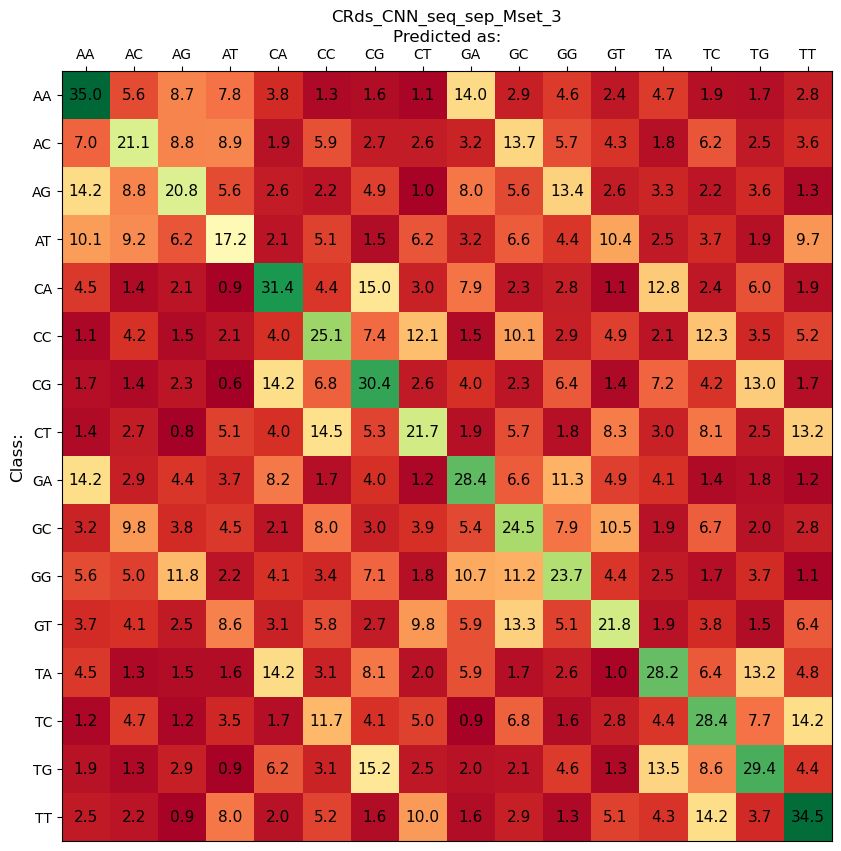

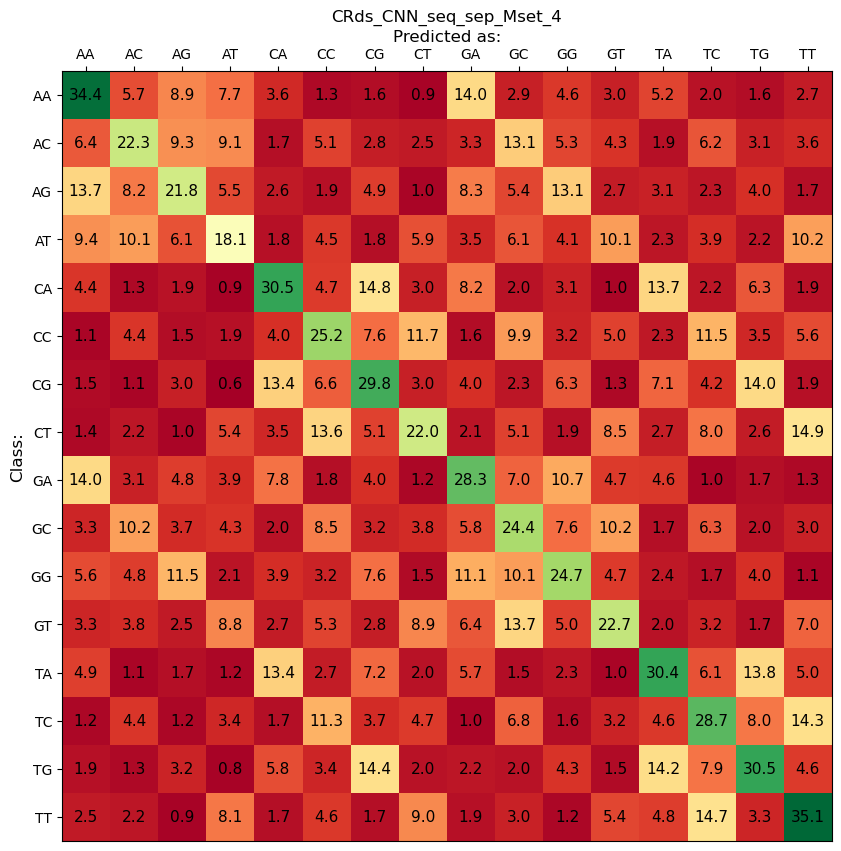

In [31]:
# plot confusion matrices

for id, df in all_confusion_matrices.items():
    plt_conf_mat(df, id)

## Save plots and models

In [32]:
# Save plots

# Whether to add timestamp to the file names -- for unambiguous naming
add_stamp = True

plots_out_dir = Path("Plots_confusion_matrices")

plots_out_dir.mkdir(parents=True, exist_ok=True)

for id, df in all_confusion_matrices.items():
    if add_stamp:
        if all_trainers.get(id) is not None:
            t_stamp = all_trainers[id].timestamp
            out_file = plots_out_dir / Path(f"{id}_{t_stamp}.png")
        else:
            print("Keys in confusion matrices dict and trainers dict don't match. \
                  No timestamp added to file name")
            out_file = plots_out_dir / Path(f"{id}.png")
    else:
        out_file = plots_out_dir / Path(f"{id}.png")
        
    plt_conf_mat(df, title=id, out_path=out_file)
    print(f"Saved {id} confusion matrix to {out_file}")

Saved CRds_CNN_seq_sep_Mset_1 confusion matrix to Plots_confusion_matrices/CRds_CNN_seq_sep_Mset_1_21112026_15_36_17.png
Saved CRds_CNN_seq_sep_Mset_2 confusion matrix to Plots_confusion_matrices/CRds_CNN_seq_sep_Mset_2_21112026_16_10_44.png
Saved CRds_CNN_seq_sep_Mset_3 confusion matrix to Plots_confusion_matrices/CRds_CNN_seq_sep_Mset_3_21112026_16_45_02.png
Saved CRds_CNN_seq_sep_Mset_4 confusion matrix to Plots_confusion_matrices/CRds_CNN_seq_sep_Mset_4_21112026_17_19_41.png


In [33]:
# Save models 

models_out_dir = "Trained_models"

for trn_id in all_trainers:
    all_trainers[trn_id].save_model(f"{models_out_dir}/{trn_id}.pt", with_info=True)
    print(f"Saved {id} model state dictionary to {models_out_dir}/{trn_id}.pt")

Saved CRds_CNN_seq_sep_Mset_4 model state dictionary to Trained_models/CRds_CNN_seq_sep_Mset_1.pt
Saved CRds_CNN_seq_sep_Mset_4 model state dictionary to Trained_models/CRds_CNN_seq_sep_Mset_2.pt
Saved CRds_CNN_seq_sep_Mset_4 model state dictionary to Trained_models/CRds_CNN_seq_sep_Mset_3.pt
Saved CRds_CNN_seq_sep_Mset_4 model state dictionary to Trained_models/CRds_CNN_seq_sep_Mset_4.pt
